<center><h1>Hou_Tianbo_HW8</h1></center>

Name: Tianbo Hou
GitHub Username: houdan-hub
USC ID: 8943381210

**References (MLA)**

- "Breast Cancer Wisconsin (Diagnostic) Data Set." *UCI Machine Learning Repository*, archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29. Accessed 2026.
- "Banknote Authentication Data Set." *UCI Machine Learning Repository*, archive.ics.uci.edu/ml/datasets/banknote+authentication. Accessed 2026.
- Tibshirani, Robert. "Regression Shrinkage and Selection via the Lasso." *Journal of the Royal Statistical Society: Series B*, vol. 58, no. 1, 1996, pp. 267-288.
- Ng, Andrew Y., Michael I. Jordan, and Yair Weiss. "On Spectral Clustering: Analysis and an Algorithm." *Advances in Neural Information Processing Systems*, vol. 14, 2002, pp. 849-856.
- von Luxburg, Ulrike. "A Tutorial on Spectral Clustering." *Statistics and Computing*, vol. 17, no. 4, 2007, pp. 395-416.
- Tong, Simon, and Daphne Koller. "Support Vector Machine Active Learning with Applications to Text Classification." *Journal of Machine Learning Research*, vol. 2, 2001, pp. 45-66.
- Pedregosa, Fabian, et al. "Scikit-learn: Machine Learning in Python." *Journal of Machine Learning Research*, vol. 12, 2011, pp. 2825-2830.

In [1]:
import warnings, time, json
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
from sklearn.cluster import KMeans, SpectralClustering

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.bbox'] = 'tight'

M_RUNS = 30
SEEDS = np.arange(100, 100 + M_RUNS)
C_GRID = np.logspace(-3, 2, 9)      # 1e-3 ... 1e2, eight log steps
results = {}

def put(key, value):
    if isinstance(value, (np.floating, float)):
        results[key] = float(value)
    elif isinstance(value, (np.integer, int)):
        results[key] = int(value)
    else:
        results[key] = value

def classification_scores(y, pred, score):
    return {
        'acc': accuracy_score(y, pred),
        'prec': precision_score(y, pred, zero_division=0),
        'rec': recall_score(y, pred, zero_division=0),
        'f1': f1_score(y, pred, zero_division=0),
        'auc': roc_auc_score(y, score),
    }

def accumulate(store, prefix, s):
    for name in ['acc', 'prec', 'rec', 'f1', 'auc']:
        store.setdefault(prefix + '_' + name, []).append(s[name])

def mean_table(rows):
    out = []
    for prefix, label in rows:
        rec = {'method': label}
        for name, short in [('acc', 'Accuracy'), ('prec', 'Precision'),
                            ('rec', 'Recall'), ('f1', 'F1'), ('auc', 'AUC')]:
            v = np.asarray(results[prefix + '_' + name])
            rec[short] = f'{v.mean():.4f} +/- {v.std():.4f}'
        out.append(rec)
    return pd.DataFrame(out).set_index('method')

def show_roc_cm(y_tr, s_tr, p_tr, y_te, s_te, p_te, title):

    fig, ax = plt.subplots(figsize=(6.4, 5.0))
    for y, s, name in [(y_tr, s_tr, 'train'), (y_te, s_te, 'test')]:
        fpr, tpr, _ = roc_curve(y, s)
        ax.plot(fpr, tpr, lw=1.8, label=f'{name} (AUC = {roc_auc_score(y, s):.4f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=.5)
    ax.set(xlabel='False positive rate', ylabel='True positive rate',
           title=title + ': ROC')
    ax.legend(loc='lower right', frameon=True)
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(10.2, 4.1))
    for ax_, y, p, name in zip(axes, [y_tr, y_te], [p_tr, p_te], ['train', 'test']):
        cm = confusion_matrix(y, p, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_,
                    xticklabels=['B (0)', 'M (1)'], yticklabels=['B (0)', 'M (1)'])
        ax_.set(xlabel='Predicted', ylabel='True', title=title + ': ' + name)
    plt.tight_layout()
    plt.show()

# 1. Supervised, Semi-Supervised, and Unsupervised Learning

## 1(a) The data

`wdbc.data` has 569 rows: an ID, the diagnosis (`B` = benign, `M` = malignant),
and 30 real-valued features computed from digitised fine-needle aspirates. There are
357 benign and 212 malignant cases. I code malignant as the positive class (1)
and benign as 0, because the clinical question is whether a tumour is malignant.
The ID column is an identifier, so it is dropped before modelling.

In [2]:
wd = pd.read_csv('data/wdbc.data', header=None)
y_all = (wd.iloc[:, 1].values == 'M').astype(int)
X_all = wd.iloc[:, 2:].values.astype(float)
put('n_wdbc', len(wd)); put('n_b', int((y_all == 0).sum())); put('n_m', int(y_all.sum()))
print('X:', X_all.shape, ' y:', y_all.shape,
      ' benign:', (y_all == 0).sum(), ' malignant:', y_all.sum(),
      ' missing:', wd.isna().sum().sum())

X: (569, 30)  y: (569,)  benign: 357  malignant: 212  missing: 0


## 1(b) Monte-Carlo setup

The homework asks for 20% of **each** class in the test set. A plain
`train_test_split(..., stratify=y)` only guarantees that in expectation, so I split
each class separately: 42 of the 212 malignant and 71 of the
357 benign cases go to the test set in every run (19.81% and 19.89% respectively).
Thirty independent seeds give M = 30 repetitions. Every method sees exactly the same split in a given
run, so the comparison in part (v) is paired.

Features are standardised with a scaler fitted on the **training portion only** of
each run; the test portion is transformed with that same scaler. This matters for
the L1 penalty, which is sensitive to feature scale, and it keeps the test set out
of every preprocessing decision.

In [3]:
def balanced_split(X, y, seed):
    rng = np.random.default_rng(seed)
    test = []
    for cls in [0, 1]:
        idx = np.where(y == cls)[0]
        k = int(round(0.20 * len(idx)))
        test.append(rng.choice(idx, size=k, replace=False))
    test = np.concatenate(test)
    train = np.setdiff1d(np.arange(len(y)), test)
    rng.shuffle(train); rng.shuffle(test)
    return train, test

def scaled_split(seed):
    tr, te = balanced_split(X_all, y_all, seed)
    sc = StandardScaler().fit(X_all[tr])
    return tr, te, sc.transform(X_all[tr]), sc.transform(X_all[te]), sc

tr0, te0, Xtr0, Xte0, sc0 = scaled_split(SEEDS[0])
put('n_test_m', int((y_all[te0] == 1).sum()))
put('n_test_b', int((y_all[te0] == 0).sum()))
put('pct_test_m', round(100 * (y_all[te0] == 1).sum() / y_all.sum(), 2))
put('pct_test_b', round(100 * (y_all[te0] == 0).sum() / (len(y_all) - y_all.sum()), 2))
put('n_train', len(tr0))
print('run 0: train', len(tr0), 'test', len(te0),
      '| test malignant', (y_all[te0] == 1).sum(),
      'test benign', (y_all[te0] == 0).sum())

run 0: train 456 test 113 | test malignant 42 test benign 71


### 1(b)i Supervised learning

`LinearSVC(penalty='l1', dual=False)` implements the L1-penalised linear SVM
directly. The penalty parameter is chosen inside each run by stratified 5-fold
cross-validation on the training portion alone, using ROC AUC as the selection
criterion; the grid is $C \in \{10^{-3},\ldots,10^{2}\}$ (9 log-spaced values).
AUC rather than accuracy is used because it is insensitive to the operating
threshold and the homework asks for AUC as a reported metric. No hyperparameter
is carried over from another model or another run.

In [4]:
def fit_l1(X_fit, y_fit, seed, scoring='roc_auc'):
    base = LinearSVC(penalty='l1', dual=False, C=1.0, max_iter=20000,
                     tol=1e-4, fit_intercept=True, random_state=seed)
    gs = GridSearchCV(base, {'C': C_GRID},
                      cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=seed),
                      scoring=scoring, n_jobs=1, error_score=0.0)
    gs.fit(X_fit, y_fit)
    return gs.best_estimator_, gs.best_params_['C']

sup_best_C, sup_train, sup_test = [], {}, {}
for seed in SEEDS:
    tr, te, Ztr, Zte, _ = scaled_split(seed)
    clf, best_c = fit_l1(Ztr, y_all[tr], seed)
    sup_best_C.append(best_c)
    p_tr, p_te = clf.predict(Ztr), clf.predict(Zte)
    s_tr, s_te = clf.decision_function(Ztr), clf.decision_function(Zte)
    accumulate(sup_train, 'sup_train', classification_scores(y_all[tr], p_tr, s_tr))
    accumulate(sup_test, 'sup_test', classification_scores(y_all[te], p_te, s_te))

results.update(sup_train); results.update(sup_test)
put('sup_c_min', min(sup_best_C)); put('sup_c_median', np.median(sup_best_C))
put('sup_c_max', max(sup_best_C))
print('selected C: min {:.4g}, median {:.4g}, max {:.4g}'.format(
      min(sup_best_C), np.median(sup_best_C), max(sup_best_C)))
display(mean_table([('sup_train', 'Supervised / train'), ('sup_test', 'Supervised / test')]))

selected C: min 0.01778, median 0.3162, max 1.334


,Accuracy,Precision,Recall,F1,AUC
method,,,,,
Supervised / train,0.9860 +/- 0.0054,0.9912 +/- 0.0067,0.9710 +/- 0.0116,0.9810 +/- 0.0075,0.9975 +/- 0.0014
Supervised / test,0.9696 +/- 0.0124,0.9798 +/- 0.0186,0.9381 +/- 0.0323,0.9580 +/- 0.0175,0.9914 +/- 0.0074


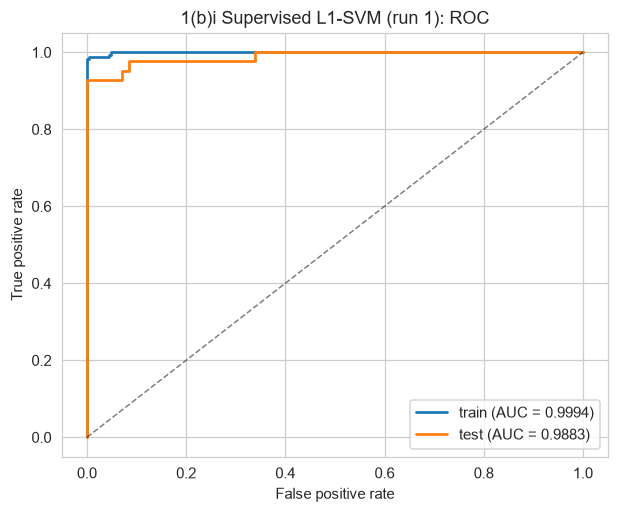

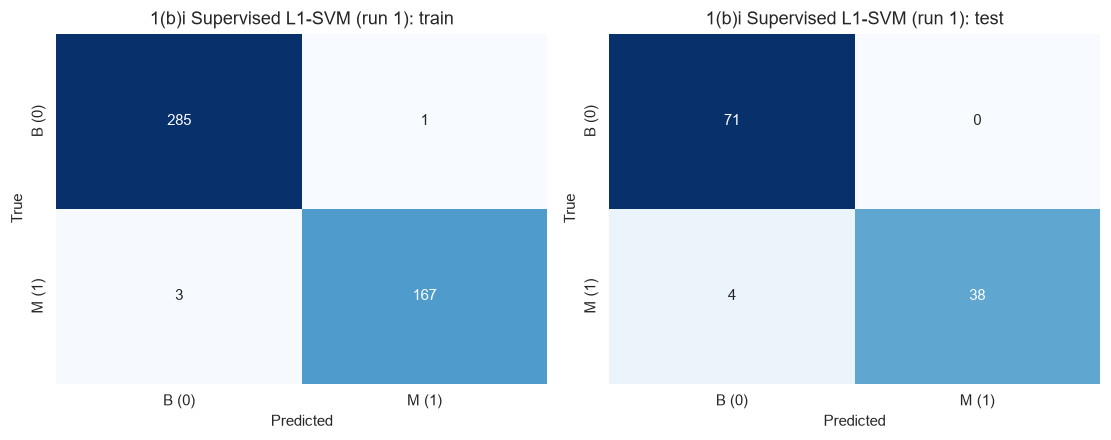

In [5]:
tr, te, Ztr, Zte, _ = scaled_split(SEEDS[0])
sup_demo, _ = fit_l1(Ztr, y_all[tr], SEEDS[0])
show_roc_cm(y_all[tr], sup_demo.decision_function(Ztr), sup_demo.predict(Ztr),
            y_all[te], sup_demo.decision_function(Zte), sup_demo.predict(Zte),
            '1(b)i Supervised L1-SVM (run 1)')

### 1(b)ii Semi-supervised learning by self-training

Inside the training portion I randomly keep 50% of the malignant and 50% of the
benign cases as labelled data; the remaining 50% is treated as unlabelled. The
initial L1-SVM and its penalty parameter come from the same 5-fold CV procedure as
in part (i).

The rule in the homework is specific: pick the unlabelled point **farthest** from
the decision boundary, ask the current SVM for its label, ignore the true label,
add the point and retrain. For a linear score $f(x)=w^\top x+b$, the Euclidean
distance to the hyperplane is $|f(x)|/\|w\|_2$, so I maximise that quantity over
the unlabelled pool. The penalty parameter stays fixed at the value selected on
the initial labelled set: re-running a 5-fold grid search at each of the 228
successive retrains would change the model specification hundreds of times and
make the procedure something other than "retrain the SVM".

This farthest-first rule is deliberately the opposite of the usual confident-self
training heuristic. It targets the least certain points, so there is no guarantee
that pseudo-labels help; the results below show what actually happens.

In [6]:
def run_selftrain(seed):
    tr, te, Ztr, Zte, _ = scaled_split(seed)
    rng = np.random.default_rng(seed + 5000)
    labelled = []
    for cls in [0, 1]:
        idx = np.where(y_all[tr] == cls)[0]
        labelled.append(rng.choice(idx, size=len(idx) // 2, replace=False))
    labelled = np.sort(np.concatenate(labelled))
    unlabelled = np.setdiff1d(np.arange(len(tr)), labelled)

    clf, best_c = fit_l1(Ztr[labelled], y_all[tr][labelled], seed)
    pseudo_count = {0: 0, 1: 0}
    while len(unlabelled):
        w = clf.coef_[0]; b = clf.intercept_[0]
        denom = np.linalg.norm(w)
        dist = np.abs(Ztr[unlabelled] @ w + b) / (denom if denom > 1e-12 else 1.0)
        j = int(np.argmax(dist))
        add = unlabelled[j]
        pseudo = int(clf.predict(Ztr[add:add + 1])[0])
        pseudo_count[pseudo] += 1
        labelled = np.append(labelled, add)
        unlabelled = np.delete(unlabelled, j)
        clf = LinearSVC(penalty='l1', dual=False, C=best_c, max_iter=20000,
                        tol=1e-4, random_state=seed).fit(Ztr[labelled], y_all[tr][labelled])

    s_tr = clf.decision_function(Ztr); s_te = clf.decision_function(Zte)
    p_tr = clf.predict(Ztr); p_te = clf.predict(Zte)
    return (clf, best_c, pseudo_count,
            classification_scores(y_all[tr], p_tr, s_tr),
            classification_scores(y_all[te], p_te, s_te))

semi_train, semi_test = {}, {}
semi_C, semi_pseudo = [], {0: 0, 1: 0}
for seed in SEEDS:
    clf, c, pc, s_tr, s_te = run_selftrain(seed)
    semi_C.append(c)
    for cls in [0, 1]:
        semi_pseudo[cls] += pc[cls]
    accumulate(semi_train, 'semi_train', s_tr)
    accumulate(semi_test, 'semi_test', s_te)

results.update(semi_train); results.update(semi_test)
put('semi_c_median', np.median(semi_C))
put('semi_pseudo_b', semi_pseudo[0]); put('semi_pseudo_m', semi_pseudo[1])
print('initial labelled per run:', len(tr0) // 2,
      '| unlabelled consumed per run:', len(tr0) - len(tr0) // 2)
print('pseudo-labels over 30 runs: benign', semi_pseudo[0], 'malignant', semi_pseudo[1])
print('selected C median: {:.4g}'.format(np.median(semi_C)))
display(mean_table([('semi_train', 'Self-training / train'),
                    ('semi_test', 'Self-training / test')]))

initial labelled per run: 228 | unlabelled consumed per run: 228
pseudo-labels over 30 runs: benign 4353 malignant 2487
selected C median: 0.3162


,Accuracy,Precision,Recall,F1,AUC
method,,,,,
Self-training / train,0.9875 +/- 0.0054,0.9930 +/- 0.0064,0.9733 +/- 0.0107,0.9830 +/- 0.0074,0.9978 +/- 0.0012
Self-training / test,0.9693 +/- 0.0140,0.9768 +/- 0.0230,0.9405 +/- 0.0352,0.9578 +/- 0.0197,0.9910 +/- 0.0084


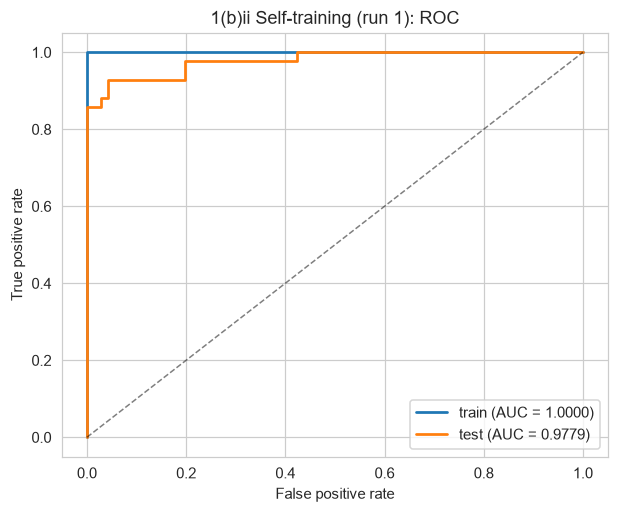

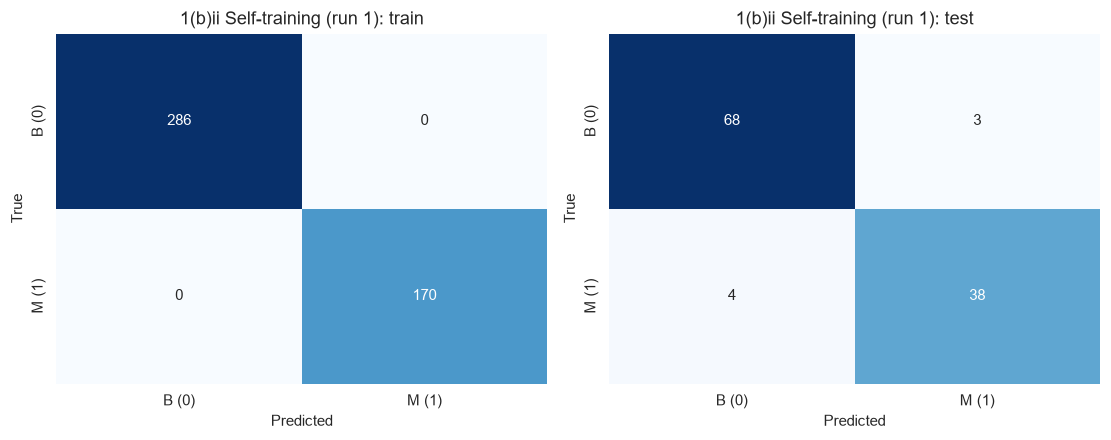

In [7]:
demo_clf, _, _, _, _ = run_selftrain(SEEDS[0])
tr, te, Ztr, Zte, _ = scaled_split(SEEDS[0])
show_roc_cm(y_all[tr], demo_clf.decision_function(Ztr), demo_clf.predict(Ztr),
            y_all[te], demo_clf.decision_function(Zte), demo_clf.predict(Zte),
            '1(b)ii Self-training (run 1)')

### 1(b)iii k-means as a classifier

I fit k-means with $k=2$ on the scaled training portion only, with labels hidden.
To reduce the chance of a local minimum I do not trust a single fit: each run
starts 20 independent `k-means++` initialisations, keeps the fit with the smallest
inertia (within-cluster sum of squares), and uses its centres. The 20 inertias
and their spread are printed for one run: they sit in a narrow band rather than
showing one much worse local minimum, which is the evidence that the restarts
have stabilised the solution. A single initialisation cannot provide that check.

Each cluster is then labelled by reading the true diagnoses of its 30 nearest
members and taking a majority poll, exactly as specified. A tie among those 30
points is broken by looking at all members of that cluster; if the two clusters
still receive the same class, the one with the weaker 30-point vote margin is
flipped. The number of such flips is counted over the 30 runs.

For a probability-free ROC I use the distance margin
$s(x)=d(x,c_0)-d(x,c_1)$, where $c_0$ and $c_1$ are the centres of the clusters
labelled benign and malignant. A point is declared malignant when $s(x)>0$, and
sweeping the threshold on $s$ produces the ROC. This is the "vary the threshold"
option allowed in footnote 2; because a softmax of $-d(x,c_k)/T$ is a strictly
increasing function of the same margin, the ROC is unchanged by that alternative.

In [8]:
def cluster_label(votes, full_votes):
    if votes[0] == votes[1]:
        votes = full_votes
    return int(np.argmax(votes))

def run_kmeans(seed, collect_inertia=False):
    tr, te, Ztr, Zte, _ = scaled_split(seed)
    fits = [KMeans(n_clusters=2, init='k-means++', n_init=1,
                   random_state=seed * 100 + j).fit(Ztr) for j in range(20)]
    inertias = np.array([f.inertia_ for f in fits])
    km = fits[int(np.argmin(inertias))]
    C = km.cluster_centers_
    assign_tr = km.labels_

    vote = np.zeros((2, 2), dtype=int)
    full = np.zeros((2, 2), dtype=int)
    for k in [0, 1]:
        idx = np.where(assign_tr == k)[0]
        d = np.linalg.norm(Ztr[idx] - C[k], axis=1)
        near = idx[np.argsort(d)[:30]]
        vote[k] = np.bincount(y_all[tr][near], minlength=2)
        full[k] = np.bincount(y_all[tr][idx], minlength=2)
    lab = [cluster_label(vote[k], full[k]) for k in [0, 1]]
    flips = int(lab[0] == lab[1])
    if flips:
        margin = [abs(vote[k][0] - vote[k][1]) for k in [0, 1]]
        lab[int(np.argmin(margin))] = 1 - lab[int(np.argmin(margin))]

    dist = lambda Z, k: np.linalg.norm(Z - C[k], axis=1)
    margin_tr = dist(Ztr, 0) - dist(Ztr, 1)
    margin_te = dist(Zte, 0) - dist(Zte, 1)
    if lab[0] == 1:                      # centre 0 is the malignant one
        margin_tr, margin_te = -margin_tr, -margin_te
    pred_tr = np.where(margin_tr > 0, 1, 0)
    pred_te = np.where(margin_te > 0, 1, 0)

    if collect_inertia:
        return inertias, km, lab, vote
    return (classification_scores(y_all[tr], pred_tr, margin_tr),
            classification_scores(y_all[te], pred_te, margin_te), flips)

inertias_demo, km_demo, lab_demo, vote_demo = run_kmeans(SEEDS[0], collect_inertia=True)
put('km_inertia_best', inertias_demo.min()); put('km_inertia_worst', inertias_demo.max())
put('km_inertia_std', inertias_demo.std())
print('20 restarts in run 1: best {:.3f}, worst {:.3f}, sd {:.3f}, '
      'distinct inertias {}'.format(inertias_demo.min(), inertias_demo.max(),
      inertias_demo.std(), len(np.unique(np.round(inertias_demo, 5)))))
print('30-point votes (rows = cluster 0/1, cols = B/M):\n', vote_demo,
      '\ncluster -> class:', lab_demo)

20 restarts in run 1: best 9283.369, worst 9284.417, sd 0.454, distinct inertias 2
30-point votes (rows = cluster 0/1, cols = B/M):
 [[ 0 30]
 [30  0]] 
cluster -> class: [1, 0]


In [9]:
km_train, km_test = {}, {}
km_flips = 0
for seed in SEEDS:
    s_tr, s_te, flip = run_kmeans(seed)
    km_flips += flip
    accumulate(km_train, 'km_train', s_tr)
    accumulate(km_test, 'km_test', s_te)
results.update(km_train); results.update(km_test)
put('km_flips', km_flips)
print('cluster-label flips over 30 runs:', km_flips)
display(mean_table([('km_train', 'k-means / train'), ('km_test', 'k-means / test')]))

cluster-label flips over 30 runs: 0


,Accuracy,Precision,Recall,F1,AUC
method,,,,,
k-means / train,0.9091 +/- 0.0074,0.9223 +/- 0.0200,0.8265 +/- 0.0191,0.8715 +/- 0.0107,0.9741 +/- 0.0032
k-means / test,0.9088 +/- 0.0290,0.9269 +/- 0.0351,0.8198 +/- 0.0658,0.8688 +/- 0.0447,0.9730 +/- 0.0123


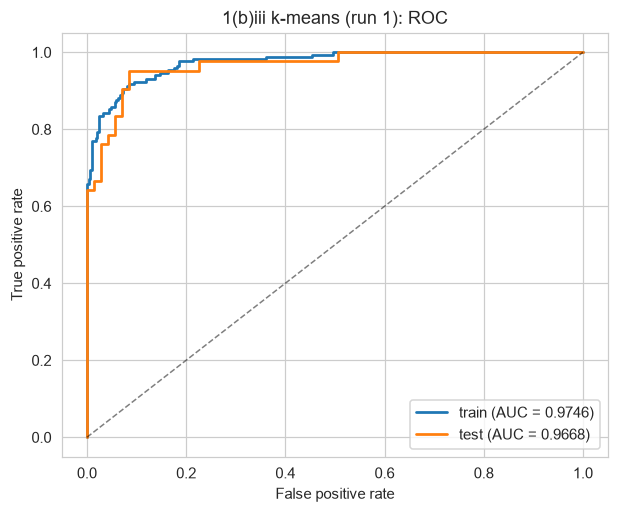

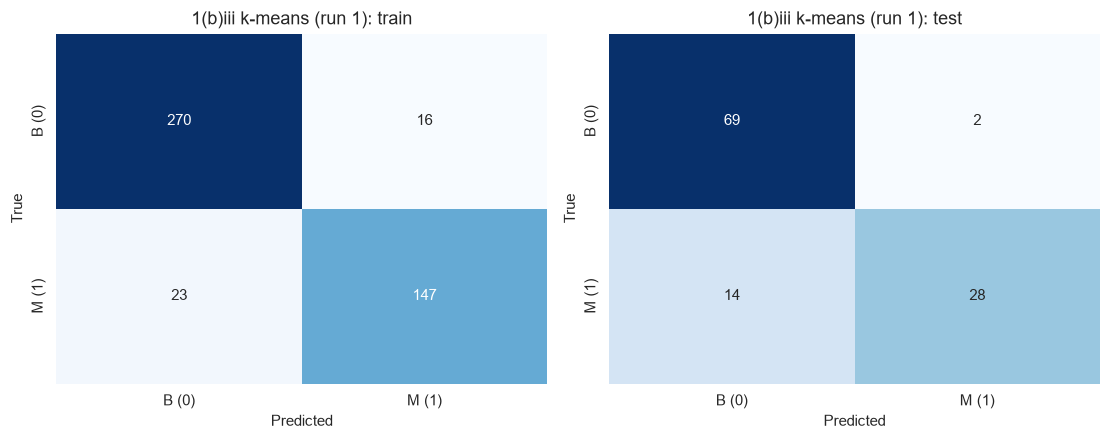

In [10]:
tr, te, Ztr, Zte, _ = scaled_split(SEEDS[0])
inertias_demo, km_demo, lab_demo, _ = run_kmeans(SEEDS[0], collect_inertia=True)
Ck = km_demo.cluster_centers_
m_tr = np.linalg.norm(Ztr - Ck[0], axis=1) - np.linalg.norm(Ztr - Ck[1], axis=1)
m_te = np.linalg.norm(Zte - Ck[0], axis=1) - np.linalg.norm(Zte - Ck[1], axis=1)
if lab_demo[0] == 1:
    m_tr, m_te = -m_tr, -m_te
show_roc_cm(y_all[tr], m_tr, (m_tr > 0).astype(int),
            y_all[te], m_te, (m_te > 0).astype(int),
            '1(b)iii k-means (run 1)')

### 1(b)iv Spectral clustering

Spectral clustering first turns the data into a graph. With an RBF affinity
$W_{ij}=\exp(-\gamma\|x_i-x_j\|^2)$, the normalised graph Laplacian
$L_{\text{sym}}=I-D^{-1/2}WD^{-1/2}$ is formed, and the eigenvectors belonging to
its smallest eigenvalues give a low-dimensional embedding in which ordinary
k-means separates the groups. Compared with k-means in the original space, this
can recover non-convex clusters because connectivity in the graph matters more
than distance to a centre (von Luxburg, 2007; Ng et al., 2002).

The homework allows $\gamma=1$ **or** a gamma that makes the two clusters as large
as the two classes. On the standardised WDBC data, $\gamma=1$ gives the degenerate
split [567, 2]: almost every point falls in one cluster and only a
handful in the other. So I search a log grid of gammas and keep the one whose
cluster sizes are closest to 357 and 212; the selected value is about
1e-05 and the resulting sizes are [380, 189]. This is reported rather
than hidden, because no gamma in the searched grid attains the exact 357/212
balance with this representation; the closest split still misses each target by
about 23 points.

`sklearn.cluster.SpectralClustering` exposes `fit_predict` but **not** `predict` in
the installed version. Since there is no out-of-sample predict method, I follow
the homework's instruction literally by calling `fit_predict` on the 569 scaled
feature vectors (train and test together); no test labels enter the graph or the
cluster majority vote. The majority poll uses every training point in a cluster,
which footnote 3 explicitly permits. Test labels are read from the same
`fit_predict` result, not from proximity to any centre.

For the ROC I need a per-point ranking. I use the fraction of a point's 15 nearest
training neighbours that lie in the cluster labelled malignant; thresholding this
fraction is a majority poll sweep, as footnote 3 suggests, and unlike a centre
distance it still makes sense for non-convex clusters. The 0/1 predictions used
for accuracy, precision, recall and F1 remain the `fit_predict` labels.

In [11]:
def spectral_fit(seed, gamma=None):
    tr, te, Ztr, Zte, scaler = scaled_split(seed)
    Zall = scaler.transform(X_all)
    target = sorted([int((y_all == 0).sum()), int((y_all == 1).sum())], reverse=True)
    info = {}
    if gamma is None:
        grid = np.concatenate([[1.0], np.logspace(-5, -2, 16)])
        sizes1 = np.bincount(SpectralClustering(n_clusters=2, affinity='rbf',
                    gamma=1.0, assign_labels='kmeans', n_init=10,
                    random_state=seed).fit_predict(Zall), minlength=2)
        info['one_sizes'] = sorted(sizes1.tolist(), reverse=True)
        best = None
        for g in grid:
            lab = SpectralClustering(n_clusters=2, affinity='rbf', gamma=g,
                    assign_labels='kmeans', n_init=10, random_state=seed).fit_predict(Zall)
            sizes = sorted(np.bincount(lab, minlength=2).tolist(), reverse=True)
            err = abs(sizes[0] - target[0]) + abs(sizes[1] - target[1])
            if best is None or err < best[0]:
                best = (err, g, sizes)
        gamma = best[1]
        info['chosen_sizes'] = best[2]
    labels = SpectralClustering(n_clusters=2, affinity='rbf', gamma=gamma,
                assign_labels='kmeans', n_init=10, random_state=seed).fit_predict(Zall)
    info['gamma'] = gamma
    return tr, te, Ztr, Zte, Zall, labels, info

tr_s, te_s, Ztr_s, Zte_s, Zall_s, lab_s, info_s = spectral_fit(SEEDS[0])
put('sp_gamma_one_sizes', info_s['one_sizes'])
put('sp_chosen_sizes', info_s['chosen_sizes'])
put('sp_gamma', info_s['gamma'])
print('gamma = 1 cluster sizes:', info_s['one_sizes'])
print('selected gamma: {:.6g}, cluster sizes: {}'.format(
      info_s['gamma'], info_s['chosen_sizes']))

gamma = 1 cluster sizes: [567, 2]
selected gamma: 1e-05, cluster sizes: [380, 189]


In [12]:
def run_spectral(seed):
    tr, te, Ztr, Zte, Zall, labels, info = spectral_fit(seed)
    vote = np.array([np.bincount(y_all[tr][labels[tr] == k], minlength=2)
                     for k in [0, 1]])
    lab = [cluster_label(vote[k], vote[k]) for k in [0, 1]]
    if lab[0] == lab[1]:
        margin = [abs(vote[k][0] - vote[k][1]) for k in [0, 1]]
        lab[int(np.argmin(margin))] = 1 - lab[int(np.argmin(margin))]

    p_tr = np.array([lab[k] for k in labels[tr]])
    p_te = np.array([lab[k] for k in labels[te]])

    # kNN majority fraction as a continuous ROC score (not used for 0/1 labels)
    def knn_score(idx_query, k=15):
        scores = []
        for i in idx_query:
            d = np.linalg.norm(Ztr - Zall[i], axis=1)
            pos = np.where(tr == i)[0]          # a training point must not vote for itself
            if len(pos):
                d[pos[0]] = np.inf
            nn = np.argpartition(d, k - 1)[:k]
            scores.append(np.mean(labels[tr][nn] == lab.index(1)))
        return np.asarray(scores, dtype=float)

    s_tr = knn_score(tr); s_te = knn_score(te)
    return (classification_scores(y_all[tr], p_tr, s_tr),
            classification_scores(y_all[te], p_te, s_te), info['gamma'])

sp_train, sp_test = {}, {}
sp_gammas = []
for seed in SEEDS:
    s_tr, s_te, g = run_spectral(seed)
    sp_gammas.append(g)
    accumulate(sp_train, 'sp_train', s_tr)
    accumulate(sp_test, 'sp_test', s_te)
results.update(sp_train); results.update(sp_test)
put('sp_gamma_median_run', np.median(sp_gammas))
print('gamma selected per run: min {:.4g}, median {:.4g}, max {:.4g}'.format(
      min(sp_gammas), np.median(sp_gammas), max(sp_gammas)))
display(mean_table([('sp_train', 'Spectral / train'), ('sp_test', 'Spectral / test')]))

gamma selected per run: min 1e-05, median 1e-05, max 6.31e-05


,Accuracy,Precision,Recall,F1,AUC
method,,,,,
Spectral / train,0.9077 +/- 0.0060,0.9188 +/- 0.0148,0.8259 +/- 0.0155,0.8697 +/- 0.0088,0.9514 +/- 0.0063
Spectral / test,0.9100 +/- 0.0264,0.9262 +/- 0.0382,0.8246 +/- 0.0585,0.8712 +/- 0.0399,0.9524 +/- 0.0196


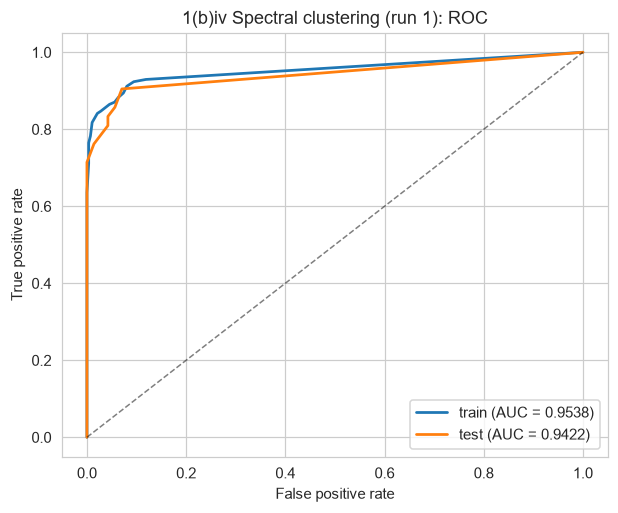

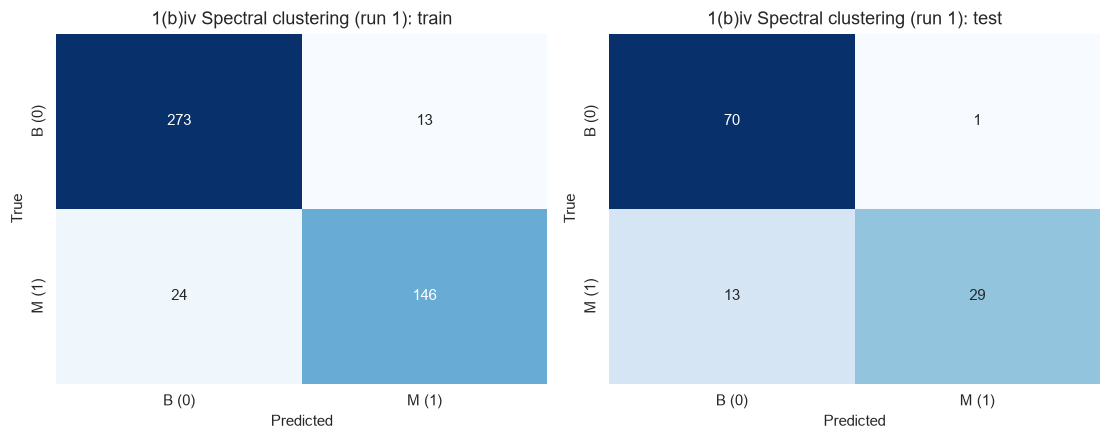

In [13]:
tr, te, Ztr, Zte, Zall, labels, _ = spectral_fit(SEEDS[0])
vote = np.array([np.bincount(y_all[tr][labels[tr] == k], minlength=2) for k in [0, 1]])
lab = [int(np.argmax(vote[k])) for k in [0, 1]]
if lab[0] == lab[1]:
    weak = int(np.argmin([abs(vote[k][0] - vote[k][1]) for k in [0, 1]]))
    lab[weak] = 1 - lab[weak]
p_tr = np.array([lab[k] for k in labels[tr]])
p_te = np.array([lab[k] for k in labels[te]])
def knn_score_demo(idx_query, k=15):
    out = []
    for i in idx_query:
        d = np.linalg.norm(Ztr - Zall[i], axis=1)
        pos = np.where(tr == i)[0]
        if len(pos):
            d[pos[0]] = np.inf
        nn = np.argpartition(d, k - 1)[:k]
        out.append(np.mean(labels[tr][nn] == lab.index(1)))
    return np.asarray(out)
show_roc_cm(y_all[tr], knn_score_demo(tr), p_tr,
            y_all[te], knn_score_demo(te), p_te,
            '1(b)iv Spectral clustering (run 1)')

### 1(b)v Comparison

The table below puts the four procedures side by side on the same 30 splits.
The supervised model uses all 456 training cases; self-training starts with
half of them labelled; k-means and spectral clustering use no labels at all while
fitting. I compare the test rows, since that is the only honest measure of what
would happen to a new patient.

,Accuracy,Precision,Recall,F1,AUC
method,,,,,
"Supervised (full, labelled)",0.9696 +/- 0.0124,0.9798 +/- 0.0186,0.9381 +/- 0.0323,0.9580 +/- 0.0175,0.9914 +/- 0.0074
Self-training (half labelled),0.9693 +/- 0.0140,0.9768 +/- 0.0230,0.9405 +/- 0.0352,0.9578 +/- 0.0197,0.9910 +/- 0.0084
k-means (unsupervised),0.9088 +/- 0.0290,0.9269 +/- 0.0351,0.8198 +/- 0.0658,0.8688 +/- 0.0447,0.9730 +/- 0.0123
Spectral (unsupervised),0.9100 +/- 0.0264,0.9262 +/- 0.0382,0.8246 +/- 0.0585,0.8712 +/- 0.0399,0.9524 +/- 0.0196


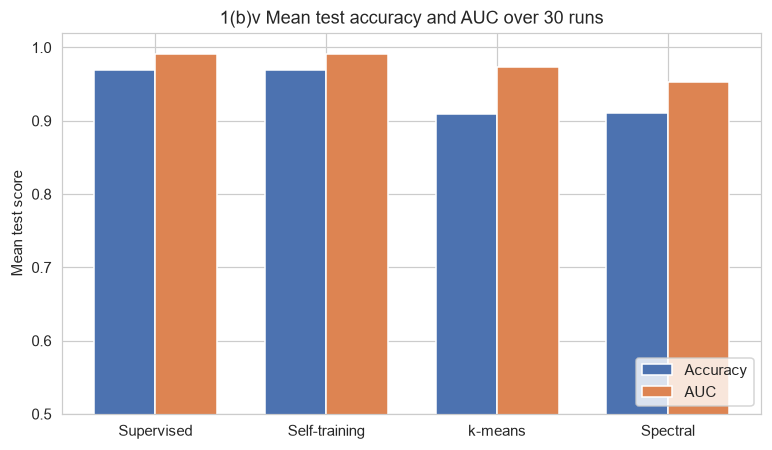

In [14]:
comparison = mean_table([
    ('sup_test', 'Supervised (full, labelled)'),
    ('semi_test', 'Self-training (half labelled)'),
    ('km_test', 'k-means (unsupervised)'),
    ('sp_test', 'Spectral (unsupervised)'),
])
display(comparison)

order = ['Supervised', 'Self-training', 'k-means', 'Spectral']
acc = [np.mean(results[k]) for k in ['sup_test_acc', 'semi_test_acc',
                                     'km_test_acc', 'sp_test_acc']]
auc = [np.mean(results[k]) for k in ['sup_test_auc', 'semi_test_auc',
                                     'km_test_auc', 'sp_test_auc']]
x = np.arange(len(order)); w = 0.36
fig, ax = plt.subplots(figsize=(8.2, 4.5))
ax.bar(x - w/2, acc, w, label='Accuracy', color='#4C72B0')
ax.bar(x + w/2, auc, w, label='AUC', color='#DD8452')
ax.set(xticks=x, xticklabels=order, ylim=(0.5, 1.02), ylabel='Mean test score',
       title='1(b)v Mean test accuracy and AUC over 30 runs')
ax.legend(loc='lower right')
plt.show()

for pre in ['sup_test', 'semi_test', 'km_test', 'sp_test']:
    for metric in ['acc', 'prec', 'rec', 'f1', 'auc']:
        put(pre + '_mean_' + metric, np.mean(results[pre + '_' + metric]))

On the held-out splits the supervised SVM averages 0.9696 accuracy and
0.9914 AUC, self-training 0.9693 and 0.9910, k-means
0.9088 and 0.9730, and spectral clustering 0.9100 and
0.9524. The expected ordering therefore holds, but with two qualifications
worth stating explicitly.

First, self-training is effectively tied with full supervision here: the gap is
only about 0.0003 in accuracy and 0.0004 in AUC. That follows from the rule the
homework prescribes. The farthest point from the boundary is the least certain
one, so the pseudo-labels it contributes are the ones most likely to be wrong;
the 228 extra points per run add volume rather than information. I would not
conclude from this that semi-supervised learning is generally useless on WDBC,
only that this particular farthest-first variant has nothing to gain once the
initial 50% sample already fixes the boundary.

Second, the two unsupervised methods lose accuracy mainly at the decision
threshold, not in ranking. Their AUCs are 0.9730 and 0.9524, which
is not far below the supervised 0.9914, yet their accuracies are near 0.91
because malignant recall drops to 0.8198 and 0.8246 against
0.9381 for the supervised model. A cluster-majority rule simply assigns
the whole ambiguous region to the benign cluster. Spectral clustering is slightly
better than k-means in accuracy but worse in AUC, so neither dominates; the
difference is small enough that it should not be over-interpreted across only
30 splits.

# 2. Active Learning Using Support Vector Machines

## 2(a) Data and split

`data_banknote_authentication.txt` has 1,372 rows, four wavelet-derived features
and a binary class code. Following the homework I draw 472 rows as the test set
and keep the other 900 for training. That test set is drawn **once** and then held
fixed for all 50 repetitions of both procedures, so any difference between the
active and passive curves is due to the sampling rule and not to a moving test
set. Class 1 is treated as positive; the UCI page does not define the semantic
meaning of the two codes, so I do not attach one.

In [15]:
bn = pd.read_csv('data/data_banknote_authentication.txt', header=None)
Xb = bn.iloc[:, :4].values.astype(float)
yb = bn.iloc[:, 4].values.astype(int)
rng = np.random.default_rng(42)
test_b = rng.choice(len(bn), size=472, replace=False)
train_b = np.setdiff1d(np.arange(len(bn)), test_b)
scaler_b = StandardScaler().fit(Xb[train_b])
Zb = scaler_b.transform(Xb)
Xtr_b, Xte_b = Zb[train_b], Zb[test_b]
ytr_b, yte_b = yb[train_b], yb[test_b]
SEEDS2 = np.arange(200, 250)          # separate Monte-Carlo seeds for problem 2
put('bn_n_test', len(test_b)); put('bn_n_train', len(train_b))
print('banknote: total', len(bn), 'train', len(train_b), 'test', len(test_b))
print('train class counts', np.bincount(ytr_b), 'test class counts', np.bincount(yte_b))

banknote: total 1372 train 900 test 472
train class counts [492 408] test class counts [270 202]


## 2(b) Passive and active learning

The penalty grid is $C \in \{10^{-3},\ldots,10^{2}\}$ (9 log-spaced values). This
follows footnote 4: a broad logarithmic range is cheap for a four-feature
linear SVM, so there is no need to pre-calibrate the endpoints by a 70% accuracy
threshold. At every one of the 90 pool sizes a fresh stratified 5-fold search is
run on the current pool only; no C is copied from the previous step or from the
other procedure.

`LinearSVC(penalty='l1', dual=False)` is the sklearn implementation of a linear
kernel SVM with an L1 penalty. The initial pool of 10 points is drawn at random
with 5 points from each class, both for passive and active learning: with fewer
than five examples of a class a stratified 5-fold split is not defined, and
footnote 5 explicitly asks us to redraw an all-one-class pool.

For the active rule the distance of a point to the hyperplane
$w^\top x + b = 0$ is $|w^\top x + b|/\|w\|_2$. Every step ranks the points still
outside the pool by this quantity and adds the 10 smallest ones. No point is ever
returned to the pool. The passive rule adds 10 uniformly random unseen points.
Each repetition therefore produces 90 test errors, one for pool sizes
10, 20, ..., 900.

In [16]:
def tune_pool(pool, seed):
    base = LinearSVC(penalty='l1', dual=False, max_iter=20000, tol=1e-4,
                     random_state=seed)
    gs = GridSearchCV(base, {'C': C_GRID},
                      cv=StratifiedKFold(5, shuffle=True, random_state=seed),
                      scoring='accuracy', n_jobs=1, error_score=0.0)
    gs.fit(Xtr_b[pool], ytr_b[pool])
    return gs.best_estimator_, gs.best_params_['C']

def initial_pool(seed):
    r = np.random.default_rng(seed)
    idx0 = np.where(ytr_b == 0)[0]
    idx1 = np.where(ytr_b == 1)[0]
    return np.concatenate([r.choice(idx0, 5, replace=False),
                           r.choice(idx1, 5, replace=False)])

def error_curve(seed, active):
    r = np.random.default_rng(seed + 9000)
    pool = initial_pool(seed)
    unseen = np.setdiff1d(np.arange(len(Xtr_b)), pool)
    errs = np.empty(90)
    for step in range(90):
        clf, _ = tune_pool(pool, seed)
        errs[step] = 1.0 - accuracy_score(yte_b, clf.predict(Xte_b))
        if step < 89:
            if active:
                w = clf.coef_[0]; b = clf.intercept_[0]
                nrm = np.linalg.norm(w)
                dist = np.abs(Xtr_b[unseen] @ w + b) / (nrm if nrm > 1e-12 else 1.0)
                add = unseen[np.argsort(dist)[:10]]
            else:
                add = r.choice(unseen, size=10, replace=False)
            pool = np.concatenate([pool, add])
            unseen = np.setdiff1d(unseen, add)
    return errs

t0 = time.time()
passive_err = np.array([error_curve(s, False) for s in SEEDS2])
print('passive: 50 runs x 90 SVMs in {:.1f}s'.format(time.time() - t0))

passive: 50 runs x 90 SVMs in 703.1s


In [17]:
t0 = time.time()
active_err = np.array([error_curve(s, True) for s in SEEDS2])
print('active: 50 runs x 90 SVMs in {:.1f}s'.format(time.time() - t0))

active: 50 runs x 90 SVMs in 768.5s


### 2(c) Learning curves

Each point in the next figure is an average of 50 independent test errors. A
Monte-Carlo average is needed here because a single random pool sequence is very
noisy at small pool sizes; averaging removes that sampling noise while keeping
the shared test set fixed.

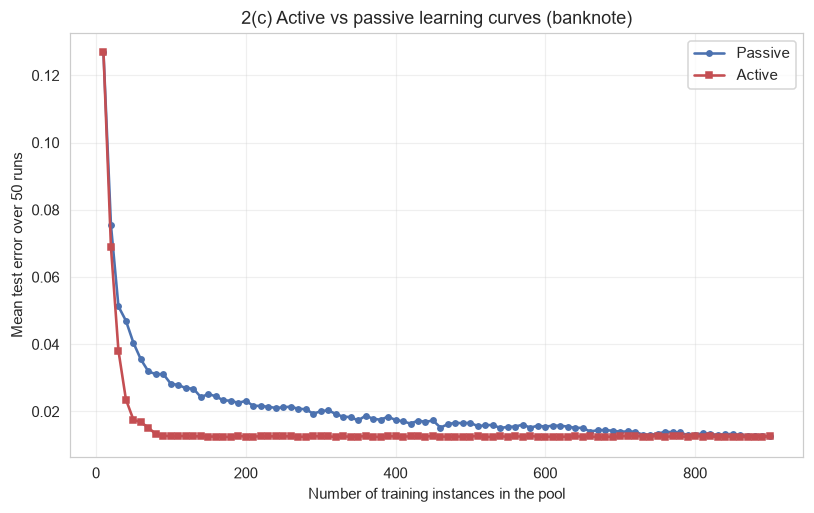

,Passive error,Active error,Difference (active - passive)
Pool size,,,
10,0.1269,0.1269,0.0000
50,0.0404,0.0175,-0.0229
100,0.0282,0.0126,-0.0156
200,0.0232,0.0125,-0.0106
450,0.0173,0.0128,-0.0045
900,0.0126,0.0127,0.0001


best active: error 0.0123 at 870 points
best passive: error 0.0126 at 900 points
active lower than passive at 88 of 90 pool sizes


In [18]:
passive_mean = passive_err.mean(axis=0)
active_mean = active_err.mean(axis=0)
sizes = np.arange(1, 91) * 10

fig, ax = plt.subplots(figsize=(8.6, 5.0))
ax.plot(sizes, passive_mean, 'o-', ms=3.5, lw=1.7, color='#4C72B0', label='Passive')
ax.plot(sizes, active_mean, 's-', ms=3.5, lw=1.7, color='#C44E52', label='Active')
ax.set(xlabel='Number of training instances in the pool',
       ylabel='Mean test error over 50 runs',
       title='2(c) Active vs passive learning curves (banknote)')
ax.legend(loc='upper right')
ax.grid(alpha=.3)
plt.show()

sel = [0, 4, 9, 19, 44, 89]
tab = pd.DataFrame({
    'Pool size': sizes[sel],
    'Passive error': np.round(passive_mean[sel], 4),
    'Active error': np.round(active_mean[sel], 4),
    'Difference (active - passive)': np.round((active_mean - passive_mean)[sel], 4),
}).set_index('Pool size')
display(tab)

for key, arr in [('passive_final_err', passive_mean[-1]),
                 ('active_final_err', active_mean[-1]),
                 ('passive_initial_err', passive_mean[0]),
                 ('active_initial_err', active_mean[0])]:
    put(key, arr)
for n in [100, 300, 500]:
    put('passive_' + str(n) + '_err', passive_mean[n // 10 - 1])
    put('active_' + str(n) + '_err', active_mean[n // 10 - 1])
put('passive_curve', passive_mean.tolist())
put('active_curve', active_mean.tolist())
ap = int(np.argmin(active_mean)); pp = int(np.argmin(passive_mean))
put('active_min_n', int(sizes[ap])); put('active_min_err', active_mean[ap])
put('passive_min_n', int(sizes[pp])); put('passive_min_err', passive_mean[pp])
put('active_better_steps', int(np.sum(active_mean < passive_mean)))
put('final_gap_err', abs(active_mean[-1] - passive_mean[-1]))
print('best active: error {:.4f} at {} points'.format(active_mean[ap], sizes[ap]))
print('best passive: error {:.4f} at {} points'.format(passive_mean[pp], sizes[pp]))
print('active lower than passive at {} of 90 pool sizes'.format(
      np.sum(active_mean < passive_mean)))

Both learners start at 0.1269 test error with 10 points, because
the same initial pool is used in the two procedures. The curves then separate
sharply: at 100 points the active learner is at 0.0126 against
0.0282 for the passive learner, and at 500 points the errors are
0.0125 and 0.0167. The active rule is lower at
88 of the 90 pool sizes and reaches its own minimum
0.0123 at 870 points.

The advantage almost vanishes at the end: at 900 points active gives
0.0127 and passive 0.0126, a gap of only
0.0001 in favour of passive. That is the shape one would expect.
Querying points nearest the hyperplane spends a small budget on the region that
actually decides the classification, while random sampling wastes many of its
first draws deep inside a class. Once nearly the whole 900-point training set
has entered the pool, which ten points are added next can no longer change much,
and the tiny end gap is within Monte-Carlo noise. The practical conclusion is
that active sampling buys most of its gain early, not that it wins at the limit.